# Challenge 4 – Orientation normalisation by registration
**Group:** (names) &nbsp; **N =** (2 or 3)

Goal: every part in a canonical pose – **nuts**: one side parallel to the horizontal axis; **screws**: longest axis vertical, head on top.

## Registration formulation
| Element | Choice |
|---|---|
| **Moving image** | binary silhouette of the part (from the label image), resampled so that its size matches the template and slightly blurred (σ = 2 px) |
| **Fixed image** | class template in canonical pose: *nut* = regular hexagon with a horizontal side; *screw* = vertical silhouette with a wide head on top and a pointed tip at the bottom |
| **Transformation** | 2-D rotation θ about the part centroid + translation (t<sub>x</sub>, t<sub>y</sub>) + scaling (isotropic for nuts, axis-aligned sx, sy for screws, because screw proportions vary). Only θ is the quantity of interest; it is then applied (rotation only, no rescaling) to the full-resolution colour crop |
| **Similarity measure** | normalised cross-correlation (NCC); sum-of-squared-differences (SSD) is compared in Section 7 |
| **Optimiser** | global search over θ on a 5° grid (centroids and sizes initialised from image moments), then Powell refinement of all parameters from the best candidates |

**Symmetries.** A hexagon is invariant to 60° rotations ⇒ nut pose is defined modulo 60° and we keep the smallest rotation. A screw silhouette is only symmetric under 180° rotation up to its head: the asymmetric template (wide head, pointed tip) resolves the head/tip ambiguity.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy.optimize import minimize

SEED = 0
IN, ANN, C1, C2, OUT = Path("inputs"), Path("annotations"), Path("outputs/c1"), Path("outputs/c2"), Path("outputs/c4")
(OUT / "normalised").mkdir(parents=True, exist_ok=True)
EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# ---- parameters (justify in the report) ----
BEST_SEG     = "otsu"      # segmentation used in the final run (decision of Challenge 1)
MIN_PART_PX  = 30
SIM          = "ncc"       # similarity measure: "ncc" | "ssd"
GRID_STEP    = 5           # degrees, global search
TOPK         = 2           # candidates refined after the global search
SIGMA        = 2.0         # blur of template / moving image (template pixels)
CONF_THR     = 0.025       # nuts whose NCC landscape has a range below this are nearly circular -> orientation unreliable (chosen from the annotated nuts, see Section 4)
N_NUT_TEST, N_SCREW_TEST = 10, 14      # parts used in the known-rotation experiments
TEST_ANGLES  = np.arange(0, 360, 30)   # known rotations (degrees)

## 1. Templates and registration

In [2]:
def tpl_nut(S=128, R=50):
    img = np.zeros((S, S), np.float32); c = S / 2
    pts = np.array([[c + R*np.cos(np.radians(a)), c + R*np.sin(np.radians(a))] for a in range(0, 360, 60)])
    cv2.fillConvexPoly(img, np.round(pts).astype(np.int32), 1.0); return img          # vertices on the x axis -> horizontal sides top/bottom

def tpl_screw(S=256, cx=128):
    img = np.zeros((S, S), np.float32)
    cv2.fillPoly(img, [np.array([[cx-22, 28], [cx+22, 28], [cx+22, 46], [cx+11, 58], [cx-11, 58], [cx-22, 46]], np.int32)], 1.0)   # head
    cv2.rectangle(img, (cx-11, 58), (cx+11, 205), 1.0, -1)                                                                      # shaft
    cv2.fillPoly(img, [np.array([[cx-11, 205], [cx+11, 205], [cx, 228]], np.int32)], 1.0); return img                           # tip

TPL = {}
for kind, img in (("nut", tpl_nut()), ("screw", tpl_screw())):
    m = cv2.moments(img); TPL[kind] = dict(img=img, F=cv2.GaussianBlur(img, (0, 0), SIGMA), area=float(img.sum()), S=img.shape[0],
                                           cf=(m["m10"] / m["m00"], m["m01"] / m["m00"]))
LEN_SCREW = 200.0

def Rmat(deg):
    a = np.radians(deg); return np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])

def prep_moving(mask, kind):
    ys, xs = np.nonzero(mask); crop = mask[ys.min():ys.max()+1, xs.min():xs.max()+1].astype(np.float32)
    pts = np.c_[xs, ys].astype(np.float64); c = pts.mean(0); _, _, vt = np.linalg.svd(pts - c, full_matrices=False)
    proj = (pts - c) @ vt[0]; length = proj.max() - proj.min() + 1
    f = np.sqrt(TPL["nut"]["area"] / mask.sum()) if kind == "nut" else LEN_SCREW / length            # size initialisation (moments)
    small = np.pad(cv2.resize(crop, None, fx=f, fy=f, interpolation=cv2.INTER_AREA if f < 1 else cv2.INTER_LINEAR), 4)
    mm = cv2.moments(small); cm = (mm["m10"] / mm["m00"], mm["m01"] / mm["m00"])
    phi = np.degrees(np.arctan2(vt[0][1], vt[0][0]))                                                    # principal axis (PCA)
    return cv2.GaussianBlur(small, (0, 0), SIGMA), cm, f, phi

def ncc(a, b):
    a = a - a.mean(); b = b - b.mean(); return float((a * b).sum() / (np.sqrt((a*a).sum() * (b*b).sum()) + 1e-9))

def cost(p, W, cm, T, sim, tied):
    th, tx, ty, sx, sy = (p[0], p[1], p[2], p[3], p[3]) if tied else p
    A = np.diag([sx, sy]) @ Rmat(th); t = np.array(T["cf"]) + [tx, ty] - A @ np.array(cm)
    w = cv2.warpAffine(W, np.hstack([A, t[:, None]]).astype(np.float32), (T["S"], T["S"]), flags=cv2.INTER_LINEAR)
    return -ncc(T["F"], w) if sim == "ncc" else float(np.mean((T["F"] - w) ** 2))

def register(mask, kind, starts=None, sim=None, span=40, step=None):
    """Estimate the rotation theta (deg) that brings `mask` into the canonical pose of `kind` ('nut' | 'screw').
       starts=None -> global grid search + refinement; starts=[theta0,...] -> local refinement from the given initial guesses only."""
    sim = sim or SIM; step = step or GRID_STEP; T = TPL[kind]; tied = kind == "nut"
    W, cm, f, phi = prep_moving(mask, kind); p0 = lambda th: [th, 0, 0, 1.0] if tied else [th, 0, 0, 1.0, 1.0]
    grid = scores = None
    if starts is None:
        grid = np.arange(0, 360, step, dtype=float); scores = np.array([cost(p0(a), W, cm, T, sim, tied) for a in grid])
        starts = []
        for i in np.argsort(scores):
            if all(min(abs(grid[i] - s) % 360, 360 - abs(grid[i] - s) % 360) >= 30 for s in starts): starts.append(grid[i])
            if len(starts) >= TOPK: break
    best = None
    for th0 in starts:
        bnd = [(th0 - span, th0 + span), (-25, 25), (-25, 25), (.6, 1.6)] + ([] if tied else [(.6, 1.6)])
        r = minimize(cost, p0(th0), args=(W, cm, T, sim, tied), method="Powell", bounds=bnd, options=dict(xtol=1e-3, ftol=1e-6, maxfev=600))
        if best is None or r.fun < best.fun: best = r
    th = best.x[0] % 360
    if tied: th = ((th + 30) % 60) - 30                      # hexagon: keep the smallest equivalent rotation (period 60 deg)
    contrast = float(np.ptp(-scores)) if (scores is not None and sim == "ncc") else np.nan      # range of the similarity over theta: ~0 = orientation not defined
    return dict(theta=float(th), cost=float(best.fun), grid=grid, scores=scores, phi=float(phi), kind=kind, contrast=contrast)

## 2. Independent measurement of the residual orientation (Hough lines) and helpers
The registration uses a *template*; the check below uses only **edge lines** of the normalised silhouette (Hough transform), so it does not share the estimator's assumptions.
* nuts: orientation of the hexagon sides modulo 60° → residual = angle between the sides and the horizontal;
* screws: orientation of the shaft edges (near-vertical lines) → residual = deviation from the vertical.

In [3]:
def hough_dirs(mask, n_lines=12, min_frac=0.5):
    m = (mask > 0).astype(np.uint8) * 255
    edge = cv2.morphologyEx(m, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)); ys, xs = np.nonzero(m)
    ext = max(np.ptp(ys), np.ptp(xs)) + 1
    L = cv2.HoughLines(edge, 1, np.pi / 720, max(8, int(min_frac * ext / 3)))
    return np.array([]) if L is None else (np.degrees(L[:n_lines, 0, 1]) + 90) % 180        # line direction, 0 = horizontal

def hough_residual(mask, kind):
    d = hough_dirs(mask)
    if kind == "nut":
        return float(np.degrees(np.angle(np.exp(1j * 6 * np.radians(d)).mean())) / 6) if len(d) else np.nan
    dev = ((d - 90 + 90) % 180) - 90; dev = dev[np.abs(dev) < 25]                            # near-vertical lines only
    return float(dev.mean()) if len(dev) else np.nan

def rotate_pair(img, mask, theta):
    """Rotate a crop (img may be None) by theta about the mask centroid, no rescaling; returns tight crops."""
    ys, xs = np.nonzero(mask); y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    m = mask[y0:y1, x0:x1].astype(np.float32); c = np.array([xs.mean() - x0, ys.mean() - y0]); A = Rmat(theta)
    D = int(np.hypot(*m.shape)) + 6; t = np.array([D / 2, D / 2]) - A @ c; M = np.hstack([A, t[:, None]]).astype(np.float32)
    rm = cv2.warpAffine(m, M, (D, D), flags=cv2.INTER_LINEAR) > 0.5
    if not rm.any(): return None, None
    yy, xx = np.nonzero(rm); sl = (slice(yy.min(), yy.max() + 1), slice(xx.min(), xx.max() + 1))
    ri = None if img is None else cv2.warpAffine(img[y0:y1, x0:x1], M, (D, D), flags=cv2.INTER_LINEAR)[sl]
    return ri, rm[sl]

def wrap(x, period): return (x + period / 2) % period - period / 2

## 3. Ground-truth parts (annotated masks + head positions)

In [4]:
parts = pd.read_csv(ANN / "parts.csv") if (ANN / "parts.csv").exists() else pd.DataFrame(columns=["image", "part_id", "type", "head_x", "head_y"])
parts["stem"] = parts["image"].astype(str).map(lambda s: Path(s).stem); parts["type"] = parts["type"].astype(str).str.strip().str.lower()
gt_parts = []
for stem, g in parts.groupby("stem"):
    f = ANN / f"{stem}_labels.png"
    if not f.exists() or not any(p.stem == stem for p in IN.iterdir()): continue            # only annotated images that are present in inputs/
    lab = cv2.imread(str(f), cv2.IMREAD_UNCHANGED); lab = lab[..., 0] if lab.ndim == 3 else lab
    for r in g.itertuples():
        m = lab == int(r.part_id)
        if r.type in ("screw", "nut") and m.sum() >= MIN_PART_PX:
            gt_parts.append(dict(image=stem, part_id=int(r.part_id), type=r.type, mask=m, head=(float(r.head_x), float(r.head_y)) if r.type == "screw" and pd.notna(r.head_x) else None))
HAVE_GT = len(gt_parts) > 0
print(len(gt_parts), "annotated parts:", pd.Series([p["type"] for p in gt_parts]).value_counts().to_dict())
if not HAVE_GT: print("WARNING: no annotated images in inputs/ -> experiments are skipped; the final normalisation still runs")

85 annotated parts: {'screw': 59, 'nut': 26}


## 4. Registration of all annotated parts: residual orientation and head position
Residual = Hough-line orientation measured on the **normalised** silhouette (0° = perfect). For screws the head is also checked against the **annotated head position** (independent ground truth for the 180° ambiguity).

,count,mean,median,p95,max
type,,,,,
nut,26,2.50,0.81,12.04,19.32
screw,59,0.71,0.19,2.67,9.12


,count,mean,median,max
confident,,,,
False,6,8.10,6.37,19.32
True,20,0.82,0.55,3.52


(nuts: low-confidence = nearly circular silhouette, orientation ill-defined; the same data were used to choose CONF_THR)
screws with head on top: 59/59  | mean head tilt from vertical: 1.1 deg | parts without Hough estimate: 0


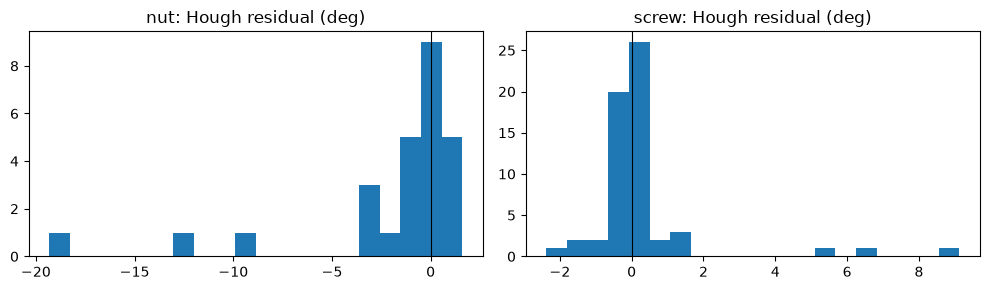

In [5]:
if HAVE_GT:
    rows = []
    for p in gt_parts:
        r = register(p["mask"], p["type"]); _, rm = rotate_pair(None, p["mask"], r["theta"])
        row = dict(image=p["image"], part_id=p["part_id"], type=p["type"], theta=r["theta"], cost=r["cost"], contrast=r["contrast"], hough_res=hough_residual(rm, p["type"]))
        if p["head"] is not None:
            ys, xs = np.nonzero(p["mask"]); v = Rmat(r["theta"]) @ (np.array(p["head"]) - [xs.mean(), ys.mean()])
            row.update(head_up=bool(v[1] < 0), head_tilt=float(np.degrees(np.arctan2(abs(v[0]), -v[1]))))
        rows.append(row)
    A = pd.DataFrame(rows); A.to_csv(OUT / "registration_gt.csv", index=False)
    A["abs_res"] = A.hough_res.abs()
    display(A.groupby("type").abs_res.agg(["count", "mean", "median", lambda s: s.quantile(.95), "max"]).rename(columns={"<lambda_0>": "p95"}).round(2))
    display(A[A.type == "nut"].assign(confident=lambda d: d.contrast >= CONF_THR).groupby("confident").abs_res.agg(["count", "mean", "median", "max"]).round(2))
    print("(nuts: low-confidence = nearly circular silhouette, orientation ill-defined; the same data were used to choose CONF_THR)")
    sc = A[A.type == "screw"]
    print(f"screws with head on top: {int(sc.head_up.sum())}/{len(sc)}  | mean head tilt from vertical: {sc.head_tilt.mean():.1f} deg | parts without Hough estimate: {int(A.hough_res.isna().sum())}")
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for a, t in zip(ax, ("nut", "screw")): a.hist(A[A.type == t].hough_res.dropna(), bins=20); a.set_title(f"{t}: Hough residual (deg)"); a.axvline(0, color="k", lw=.8)
    plt.tight_layout(); plt.savefig(OUT / "residual_hist.png", dpi=130); plt.show()

### 4.1 Similarity landscape (symmetries)

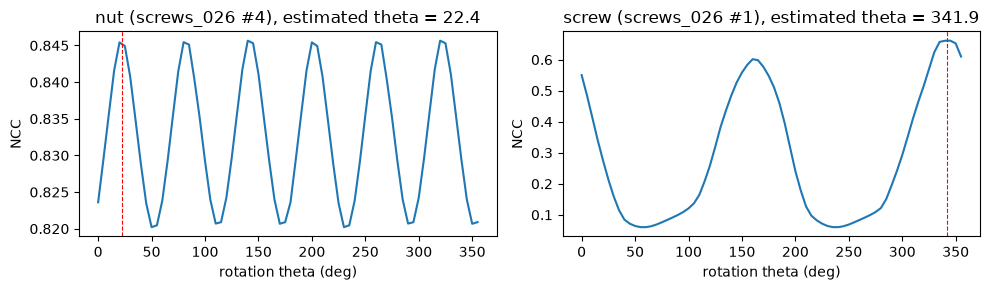

In [6]:
if HAVE_GT:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for a, t in zip(ax, ("nut", "screw")):
        p = next(q for q in gt_parts if q["type"] == t); r = register(p["mask"], t)
        a.plot(r["grid"], -r["scores"]); a.set_xlabel("rotation theta (deg)"); a.set_ylabel("NCC" if SIM == "ncc" else "-SSD"); a.set_title(f"{t} ({p['image']} #{p['part_id']}), estimated theta = {r['theta']:.1f}")
        a.axvline(r["theta"] % 360, color="r", ls="--", lw=.8)
    plt.tight_layout(); plt.savefig(OUT / "landscape.png", dpi=130); plt.show()

## 5. Test on images rotated by known angles
Each test part is rotated by α ∈ {0, 30, …, 330}° and registered again. If the estimate is consistent, **θ̂(α) + α ≡ θ̂(0)** (modulo 60° for nuts, 360° for screws).
`err` = consistency error; `hough_res` = independent residual orientation after normalisation. A screw error of ≈180° is a head/tip flip.

,n,mean_abs_err,median_abs_err,max_abs_err,within_5deg,head_flips,mean_abs_hough
type,,,,,,,
nut,120,0.14,0.06,1.08,1.00,0,1.18
screw,168,0.62,0.01,27.64,0.99,0,1.35


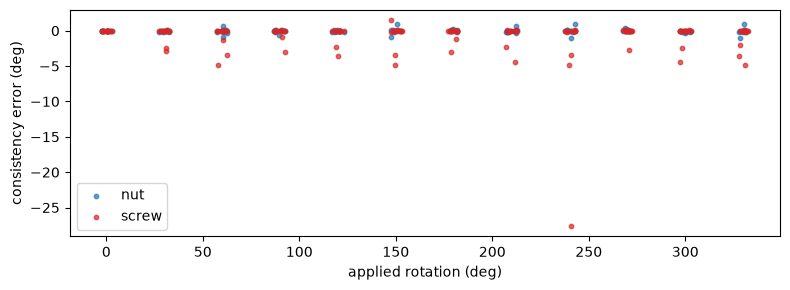

In [7]:
if HAVE_GT:
    rs = np.random.RandomState(SEED)
    pick = lambda t, n: [gt_parts[i] for i in rs.permutation([i for i, q in enumerate(gt_parts) if q["type"] == t])[:n]]
    test_parts = pick("nut", N_NUT_TEST) + pick("screw", N_SCREW_TEST)

    def rotation_test(parts_, angles, sim=None):
        rows = []
        for p in parts_:
            per = 60 if p["type"] == "nut" else 360; ref = None
            for al in angles:
                _, mr = rotate_pair(None, p["mask"], al); r = register(mr, p["type"], sim=sim)
                _, rn = rotate_pair(None, mr, r["theta"]); ref = r["theta"] if ref is None else ref
                rows.append(dict(image=p["image"], part_id=p["part_id"], type=p["type"], alpha=al, theta=r["theta"], err=wrap(r["theta"] + al - ref, per), hough_res=hough_residual(rn, p["type"])))
        return pd.DataFrame(rows)
    B = rotation_test(test_parts, TEST_ANGLES); B.to_csv(OUT / "rotation_test.csv", index=False)
    B["abs_err"] = B.err.abs(); B["flip"] = (B.type == "screw") & (B.abs_err > 150); B["ok5"] = B.abs_err < 5
    display(B.groupby("type").agg(n=("err", "size"), mean_abs_err=("abs_err", "mean"), median_abs_err=("abs_err", "median"), max_abs_err=("abs_err", "max"),
                                  within_5deg=("ok5", "mean"), head_flips=("flip", "sum"), mean_abs_hough=("hough_res", lambda s: s.abs().mean())).round(2))
    fig, ax = plt.subplots(figsize=(8, 3)); 
    for t, c in (("nut", "tab:blue"), ("screw", "tab:red")): s = B[B.type == t]; ax.scatter(s.alpha + np.random.RandomState(0).uniform(-3, 3, len(s)), s.err, s=10, c=c, label=t, alpha=.7)
    ax.set_xlabel("applied rotation (deg)"); ax.set_ylabel("consistency error (deg)"); ax.legend(); plt.tight_layout(); plt.savefig(OUT / "rotation_test.png", dpi=130); plt.show()

## 6. Dependence on the initial guess
Reference = global search. We compare (i) **local refinement only** from a single initial angle θ₀ (every 30°) with a wide search range, (ii) local refinement from the **PCA axis** (two candidates for screws; undefined for isotropic nuts), (iii) the global grid. Success = within 5° (modulo the symmetry period) of the global estimate.

In [8]:
if HAVE_GT:
    rows = []
    for p in test_parts[:N_NUT_TEST // 2] + test_parts[N_NUT_TEST:N_NUT_TEST + N_SCREW_TEST // 2 + 1]:
        per = 60 if p["type"] == "nut" else 360; ref = register(p["mask"], p["type"])
        for th0 in np.arange(0, 360, 30):
            r = register(p["mask"], p["type"], starts=[float(th0)], span=180)
            rows.append(dict(type=p["type"], mode="local, single start", offset=abs(wrap(th0 - ref["theta"], per)), err=abs(wrap(r["theta"] - ref["theta"], per))))
        if p["type"] == "screw":
            c = (90 - ref["phi"]) % 180; r = register(p["mask"], "screw", starts=[c, c + 180], span=40)
            rows.append(dict(type="screw", mode="local from PCA axis (2 candidates)", offset=np.nan, err=abs(wrap(r["theta"] - ref["theta"], 360))))
    I = pd.DataFrame(rows); I["success"] = I.err < 5
    display(I.groupby(["type", "mode"]).success.agg(["mean", "count"]).round(3))
    s = I[I["mode"] == "local, single start"].assign(bin=lambda d: pd.cut(d.offset, [-1, 30, 60, 90, 120, 150, 181]))
    display(s.groupby(["type", "bin"]).success.mean().unstack(0).round(2))

mean  count
type  mode                                            
nut   local, single start                 1.000     60
screw local from PCA axis (2 candidates)  0.750      8
      local, single start                 0.385     96

type,nut,screw
bin,,
"(-1, 30]",1.0,0.75
"(30, 60]",NaN,0.88
"(60, 90]",NaN,0.62
"(90, 120]",NaN,0.06
"(120, 150]",NaN,0.00
"(150, 181]",NaN,0.00


## 7. Similarity measure: NCC vs SSD

In [9]:
if HAVE_GT:
    sub = test_parts[:5] + test_parts[N_NUT_TEST:N_NUT_TEST + 7]; rows = []
    for sim in ("ncc", "ssd"):
        d = rotation_test(sub, np.arange(0, 360, 60), sim=sim); d["sim"] = sim; rows.append(d)
    S = pd.concat(rows); S["abs_err"] = S.err.abs()
    display(S.groupby(["sim", "type"]).abs_err.agg(["mean", "median", "max", lambda s: (s < 5).mean()]).rename(columns={"<lambda_0>": "within_5deg"}).round(2))

mean  median    max  within_5deg
sim type                                   
ncc nut    0.19    0.10   1.08         1.00
    screw  1.52    0.03  27.64         0.98
ssd nut    0.16    0.03   1.09         1.00
    screw  2.71    0.05  28.16         0.90

## 8. Normalise every part of every image in `inputs/`
Uses the Challenge 1 segmentation (`BEST_SEG`); nut/screw decision from the Challenge 2 output when available, otherwise from the aspect ratio (nuts are round: aspect < 1.4).
Each part is rotated (no rescaling) in the **full-resolution** image and saved as RGBA in `outputs/c4/normalised/`; a mosaic of all parts is saved too.

88 parts normalised -> outputs/c4/normalised | low-confidence nuts: 6


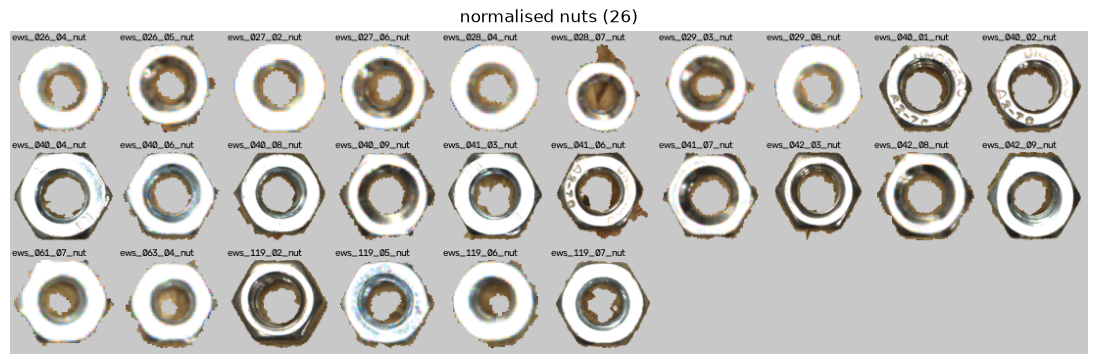

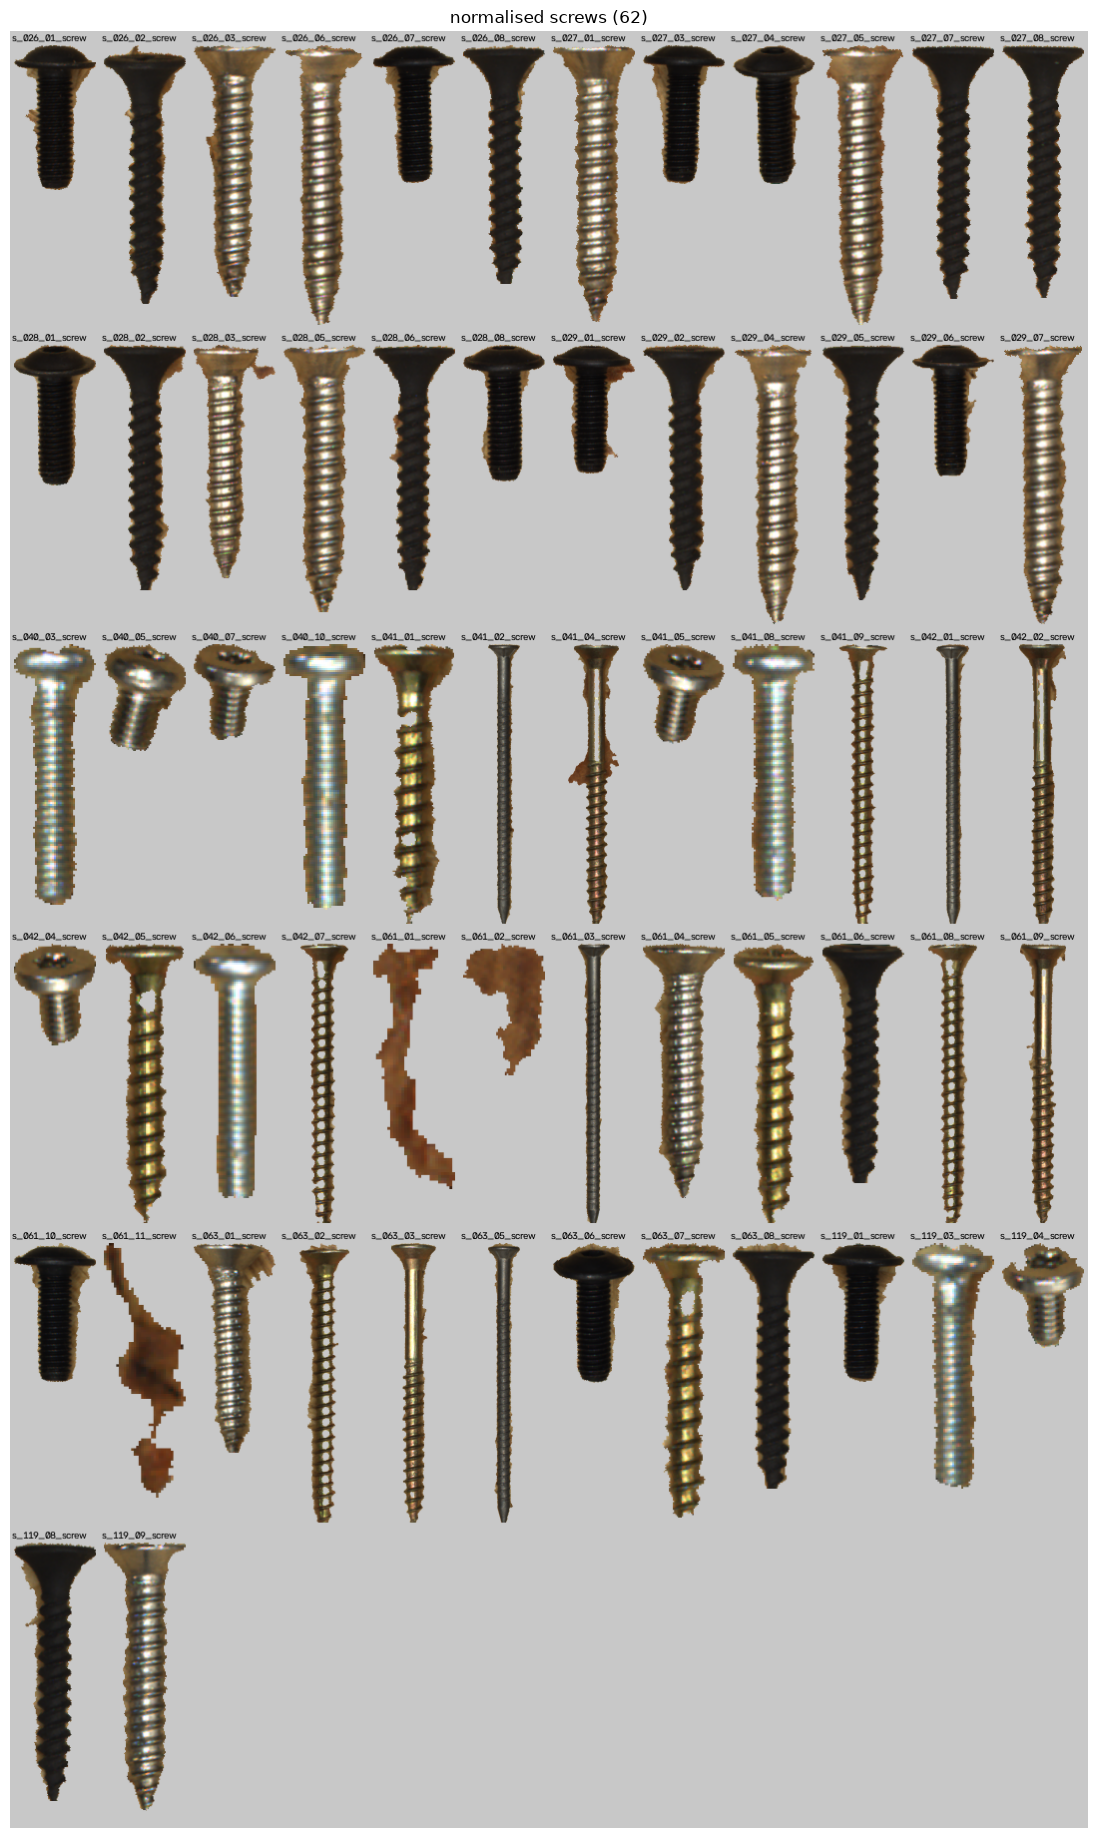

In [10]:
segs = sorted(d.name for d in C1.iterdir() if d.is_dir()) if C1.exists() else []
c2 = pd.read_csv(C2 / "classification.csv") if (C2 / "classification.csv").exists() else None
c2_map = {} if c2 is None else {(r.image, int(r.comp)): r.cls for r in c2.itertuples()}
def aspect(mask):
    ys, xs = np.nonzero(mask); pts = np.c_[xs, ys].astype(float); _, s, _ = np.linalg.svd(pts - pts.mean(0), full_matrices=False); return s[0] / max(s[1], 1e-6)

tiles = {"nut": [], "screw": []}; out_rows = []
if not segs: print("Normalisation skipped: Challenge 1 outputs not found (run C1 first).")
else:
    seg = BEST_SEG if (C1 / BEST_SEG).exists() else segs[0]
    for p in sorted(q for q in IN.iterdir() if q.suffix.lower() in EXT):
        f = C1 / seg / f"{p.stem}_labels.png"
        if not f.exists(): continue
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        lab = cv2.resize(cv2.imread(str(f), cv2.IMREAD_UNCHANGED), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST).astype(np.int32)
        for i in np.unique(lab[lab > 0]):
            m = lab == i
            if m.sum() < MIN_PART_PX: continue
            kind = c2_map.get((p.name, int(i))) or ("nut" if aspect(m) < 1.4 else "screw")
            if kind not in ("nut", "screw"): continue                       # rejected component
            r = register(m, kind); ri, rm = rotate_pair(img, m, r["theta"])
            if ri is None: continue
            _, rn = rotate_pair(None, m, r["theta"]); rgba = np.dstack([ri, (rm * 255).astype(np.uint8)])
            name = f"{p.stem}_{int(i):02d}_{kind}.png"; cv2.imwrite(str(OUT / "normalised" / name), cv2.cvtColor(rgba, cv2.COLOR_RGBA2BGRA))
            tiles[kind].append((name, rgba)); out_rows.append(dict(image=p.name, comp=int(i), type=kind, theta_deg=round(r["theta"], 2), cost=round(r["cost"], 4), contrast=round(r["contrast"], 4), low_confidence=bool(kind == "nut" and r["contrast"] < CONF_THR), hough_residual_deg=round(hough_residual(rn, kind), 2), file=name))
    pd.DataFrame(out_rows).to_csv(OUT / "normalised_parts.csv", index=False); print(len(out_rows), "parts normalised ->", OUT / "normalised", "| low-confidence nuts:", sum(r["low_confidence"] for r in out_rows))

def contact_sheet(items, tw, th, ncols):
    nrows = int(np.ceil(len(items) / ncols)); sheet = np.full((nrows * th, ncols * tw, 3), 200, np.uint8)
    for k, (name, rgba) in enumerate(items):
        h, w = rgba.shape[:2]; s = min((tw - 8) / w, (th - 20) / h); im = cv2.resize(rgba, (max(int(w * s), 1), max(int(h * s), 1)), interpolation=cv2.INTER_AREA)
        y0, x0 = (k // ncols) * th + 14, (k % ncols) * tw + (tw - im.shape[1]) // 2; a = im[..., 3:] / 255.
        sheet[y0:y0 + im.shape[0], x0:x0 + im.shape[1]] = (im[..., :3] * a + sheet[y0:y0 + im.shape[0], x0:x0 + im.shape[1]] * (1 - a)).astype(np.uint8)
        cv2.putText(sheet, name[:-4][-14:], ((k % ncols) * tw + 2, (k // ncols) * th + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.32, (0, 0, 0), 1)
    return sheet
for kind, (tw, th, nc) in {"nut": (110, 110, 10), "screw": (90, 300, 12)}.items():
    if tiles[kind]:
        sh = contact_sheet(tiles[kind], tw, th, nc); cv2.imwrite(str(OUT / f"mosaic_{kind}s.png"), cv2.cvtColor(sh, cv2.COLOR_RGB2BGR))
        plt.figure(figsize=(14, 14 * sh.shape[0] / sh.shape[1])); plt.imshow(sh); plt.axis("off"); plt.title(f"normalised {kind}s ({len(tiles[kind])})"); plt.show()

## 9. To discuss in the report (your own words)
- Formulation: fixed/moving image, transformation model (why axis-aligned anisotropic scaling for screws, isotropic for nuts), similarity measure, optimiser; why a global grid + local refinement.
- Accuracy: Hough residual statistics (nuts and screws), head-on-top rate vs annotated heads; consistency under known rotations.
- Symmetries: hexagon ⇒ 60° (6 equivalent optima in the landscape); screws ⇒ head/tip ambiguity solved only by the asymmetric template – quantify flips and say which screws are at risk (countersunk heads vs thin machine screws).
- Initial guess: local optimisation only converges inside a basin (offset table); PCA initialisation helps for elongated parts but not for nuts; global grid is robust.
- Similarity comparison NCC vs SSD. Failure analysis (tiny parts, merged/false-positive components, nuts with lost bores or specular highlights).
- Low-confidence nuts: the smallest nuts are segmented as almost circular blobs, so their orientation is not defined by the silhouette (flat similarity landscape); how would you improve it (edge/gradient cues in the colour image, higher-resolution masks)?
- Limits: silhouette-only registration; Hough estimates are noisy for parts only a few pixels wide.